# Auditoría de alertas KYC por canal
## Resumen
Experimento sintético: calibración agrupada frente a pooled; resultados calculados abajo. No es detector de fraude validado.

## Lectura de los resultados ejecutados

Se midieron falsas alertas por canal, deriva, contaminación y repetición de calibración. Los p-valores de anomalía no son probabilidades de fraude.

Resultados académicos adicionales (valores del experimento):

```json
{
  "batch_replicates": 400,
  "BY_FDR_by_rho": {
    "0.0": 0.005627525252525253,
    "0.7": 0.00045454545454545455
  }
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Contexto y método
Score fijo s=|residuo|, sin entrenamiento sobre calibración. Canales definidos antes de observar datos.

$p_g(s)=(1+\sum_i\mathbf{1}[S_{gi}\ge s])/(n_g+1)$. Alertar si $p_g\le0.05$. Empates con >= son conservadores.

Bajo intercambiabilidad de inliers dentro del canal, el rango proporciona validez marginal en calibración y nuevo caso, no una garantía condicional en la muestra fijada. No controlamos FDR de un lote ni garantizamos igualdad entre personas. 

In [1]:
from pathlib import Path
import json, csv
from IPython.display import display, Image
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
print(json.dumps(metrics,indent=2))

{
  "fpr_gap": {
    "pooled": 0.09754166666666665,
    "channel": 0.0039000000000000007
  },
  "gap_reduction": 0.09364166666666665,
  "hypothesis_passed": true,
  "elapsed_seconds": 5.231555709999839,
  "peak_tracemalloc_bytes": 1244300,
  "max_rss_kib_linux": 54704,
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
  "numpy": "2.3.5",
  "matplotlib": "3.10.8",
  "config": {
    "seeds": 60,
    "calibration_per_channel": 499,
    "test_inliers_per_channel": 2000,
    "test_outliers_per_channel": 500,
    "alpha": 0.05,
    "score_round_decimals": 1,
    "channel_scales": [
      1,
      4
    ],
    "anomaly_shift_sigma": 3,
    "drift_multiplier": 1.7,
    "sparse_calibration_per_channel": 9,
    "hypothesis": "stationary channel FPR disparity decreases by >=0.03 with channel calibration"
  }
}


## Datos y resultados
60 semillas; canales con escalas 1 y 4. Normalidad es una elección del experimento, no requisito del rango. Drift cambia solo la dispersión de inliers en evaluación. Sparse reduce calibración a 9 por canal.

{'scenario': 'stationary', 'method': 'pooled', 'channel': '0', 'kind': 'inlier', 'mean_rate': '0.0', 'seed_standard_error': '0.0'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '0', 'kind': 'outlier', 'mean_rate': '0.00016666666666666666', 'seed_standard_error': '7.19646282647288e-05'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '1', 'kind': 'inlier', 'mean_rate': '0.09754166666666665', 'seed_standard_error': '0.00190057572554009'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '1', 'kind': 'outlier', 'mean_rate': '0.9091333333333333', 'seed_standard_error': '0.002192110489744235'}
{'scenario': 'stationary', 'method': 'channel', 'channel': '0', 'kind': 'inlier', 'mean_rate': '0.0463', 'seed_standard_error': '0.0013620253280869203'}
{'scenario': 'stationary', 'method': 'channel', 'channel': '0', 'kind': 'outlier', 'mean_rate': '0.8407666666666667', 'seed_standard_error': '0.003389279098278329'}
{'scenario': 'stationary', 'method': 'channel', 'channel

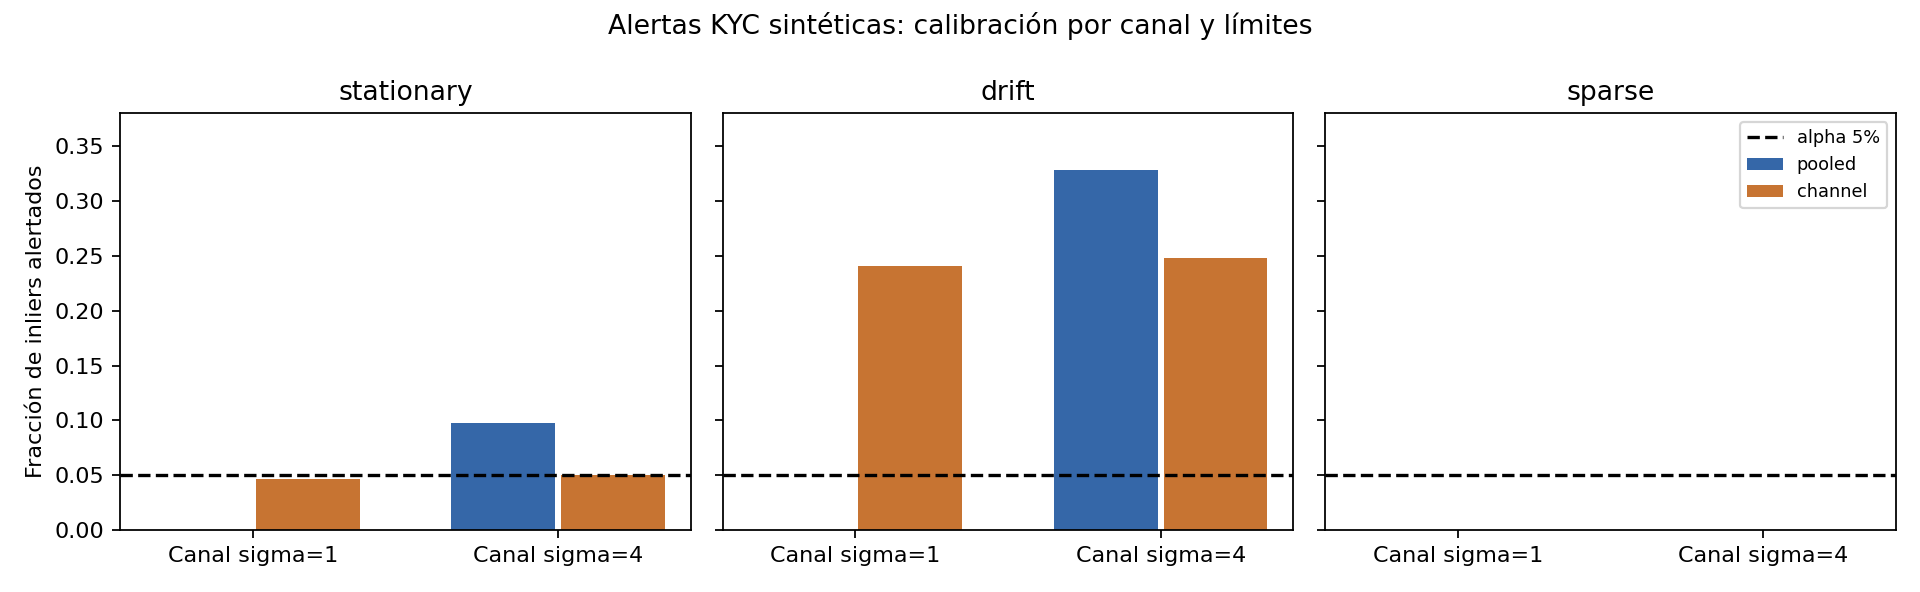

In [2]:
rows=list(csv.DictReader((root/'results/summary.csv').open()))
for row in rows: print(row)
display(Image(filename=str(root/'results/audit.png')))

## Comprobaciones

In [3]:
from src.conformal import TailCalibrator
assert TailCalibrator([1.,2.,2.,3.]).p_value(2)==.8
assert not TailCalibrator([0.]*9).alert(100,.05)
assert metrics['hypothesis_passed']
print('Checks passed; sparse abstains, drift invalidates nominal calibration.')

Checks passed; sparse abstains, drift invalidates nominal calibration.


## Conclusiones y límites
La dispersión distinta hace que un umbral global reparta mal las falsas alertas. Calibrar por canal corrige el escenario estacionario al coste de cambiar potencia por canal. No es una contribución teórica nueva: es una auditoría incremental del pipeline KYC. Deriva y pocos ejemplos muestran fallos intencionales. Siguiente paso: validar temporalmente con etiquetas aprobadas y carga de revisión humana.

## Laboratorio ampliado — derivación, usos y refutación

Experimentos adicionales del 23 de octubre de 2026. Datos sintéticos; las cifras guardadas del estudio original se conservan y las nuevas se recalculan debajo.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

### Rangos conformes por canal

$$p(s)=\frac{1+\sum_{i=1}^n1[S_i\ge s]}{n+1},\qquad alerta=1[p(s)\le\alpha].$$

Los empates se cuentan conservadoramente. El score debe estar congelado y la calibración usar casos legítimos aprobados; intercambiabilidad dentro de cada canal permite control marginal de falsas alertas para un nuevo legítimo. Esto no es probabilidad posterior de fraude, control FDR ni garantía bajo drift.

### Resolución mínima y abstención

Con menos de 19 observaciones no puede alertarse al 5% aunque el score nuevo supere a todos.

In [5]:
from src.conformal import TailCalibrator, ChannelCalibrator
resolution=pd.DataFrame({'n':[5,9,18,19,39,99,199]})
resolution['p_min']=1/(resolution.n+1)
resolution['puede_alertar_5pct']=resolution.p_min<=.05
display(resolution)
assert not TailCalibrator([0.]*18).alert(999,.05)
assert TailCalibrator([0.]*19).alert(999,.05)

,n,p_min,puede_alertar_5pct
0,5,0.166667,False
1,9,0.100000,False
2,18,0.052632,False
3,19,0.050000,True
4,39,0.025000,True
5,99,0.010000,True
6,199,0.005000,True


### Pooling frente a canales heterogéneos

El cambio de mezcla puede ocultar errores por canal. Se mantienen las mismas realizaciones para comparar políticas.

,canal,politica,FPR,n
0,A,pooled,0.000000,3000
1,A,por canal,0.039333,3000
2,B,pooled,0.084000,3000
3,B,por canal,0.048000,3000


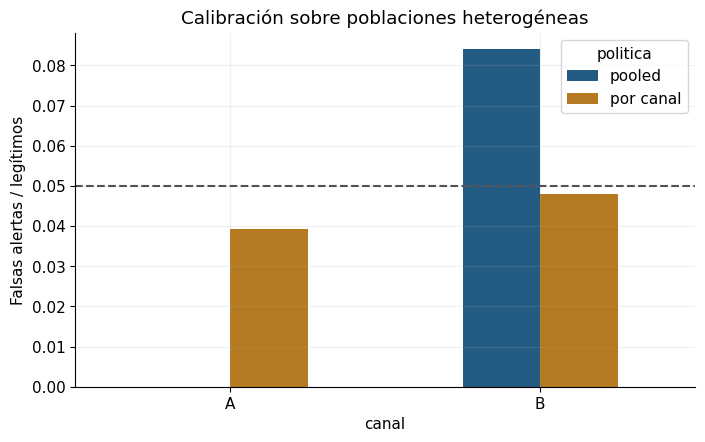

In [6]:
cal_a=rng_depth.normal(0,1,399);cal_b=rng_depth.normal(2,1.4,399)
test_a=rng_depth.normal(0,1,3000);test_b=rng_depth.normal(2,1.4,3000)
pooled=TailCalibrator(np.r_[cal_a,cal_b]);grouped=ChannelCalibrator({'A':list(cal_a),'B':list(cal_b)})
channel_rows=[]
for name,values in [('A',test_a),('B',test_b)]:
    for policy,func in [('pooled',pooled.p_value),('por canal',lambda s:grouped.p_value(name,s))]:
        alerts=np.array([func(v)<=.05 for v in values])
        channel_rows.append({'canal':name,'politica':policy,'FPR':alerts.mean(),'n':len(values)})
channel_table=pd.DataFrame(channel_rows);display(channel_table)
fig,ax=plt.subplots();channel_table.pivot(index='canal',columns='politica',values='FPR').plot.bar(ax=ax,color=[BLUE,GOLD],rot=0)
ax.axhline(.05,color=GRAY,ls='--');ax.set(ylabel='Falsas alertas / legítimos',title='Calibración sobre poblaciones heterogéneas');plt.show()

### Deriva temporal sin recalibración

La garantía depende de la distribución; una transformación monótona común conserva rangos, desplazar solo test no.

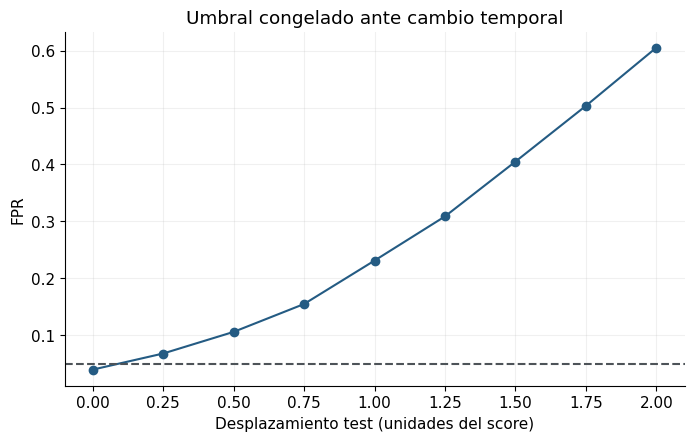

In [7]:
shifts=np.linspace(0,2,9)
drift_rates=[np.mean([grouped.p_value('A',v+d)<=.05 for v in test_a]) for d in shifts]
fig,ax=plt.subplots();ax.plot(shifts,drift_rates,'o-',color=BLUE);ax.axhline(.05,color=GRAY,ls='--')
ax.set(xlabel='Desplazamiento test (unidades del score)',ylabel='FPR',title='Umbral congelado ante cambio temporal');plt.show()
assert drift_rates[-1]>drift_rates[0]

### Carga y costo de revisión

Un umbral estadístico no administra capacidad. Este cálculo de cola es un escenario de planeación, no una eficacia observada.

In [8]:
volume=10000;minutes=8;capacity_minutes=1600
loads=pd.DataFrame({'shift':shifts,'FPR':drift_rates})
loads['alertas_esperadas']=volume*loads.FPR
loads['minutos_solicitados']=minutes*loads.alertas_esperadas
loads['minutos_sobre_capacidad']=np.maximum(loads.minutos_solicitados-capacity_minutes,0)
display(loads.round(2))
print('Capacidad de revisiones:',capacity_minutes//minutes)

Capacidad de revisiones: 200


,shift,FPR,alertas_esperadas,minutos_solicitados,minutos_sobre_capacidad
0,0.00,0.04,393.33,3146.67,1546.67
1,0.25,0.07,676.67,5413.33,3813.33
2,0.50,0.11,1056.67,8453.33,6853.33
3,0.75,0.15,1546.67,12373.33,10773.33
4,1.00,0.23,2310.00,18480.00,16880.00
5,1.25,0.31,3086.67,24693.33,23093.33
6,1.50,0.40,4050.00,32400.00,30800.00
7,1.75,0.50,5030.00,40240.00,38640.00
8,2.00,0.61,6053.33,48426.67,46826.67


### Canal desconocido y empates

No usar pooling silencioso ni convertir ausencia de soporte en normalidad.

In [9]:
try:
    grouped.p_value('nuevo',1.)
except KeyError:
    print('Canal nuevo: requiere política explícita y revisión.')
else:
    raise AssertionError('Se esperaba rechazo del canal desconocido')
assert TailCalibrator([1.]*99).p_value(1.)==1.
assert np.isclose(TailCalibrator([1.]*99).p_value(2.),.01)

Canal nuevo: requiere política explícita y revisión.


### Uso en originación

La alerta prioriza revisión de consistencia; no decide fraude ni rechazo crediticio por sí sola. La validación siguiente debe usar etiquetas maduras, canales predefinidos y fechas disponibles, medir demora/costo de revisión y distinguir fraude confirmado de falta de documentos.

### Preguntas para extender el estudio

1. ¿Qué supuesto permite el resultado y qué contraejemplo lo destruye?
2. ¿Qué cambia al separar entrenamiento, calibración y evaluación por fecha?
3. ¿Qué pérdidas, costos o acciones no están representados?
4. ¿Qué evidencia real haría abandonar este modelo?

Las salidas anteriores son el resultado de esta ejecución; las pruebas locales no establecen validez empírica.

### Contaminación de calibración

Casos anómalos incluidos como legítimos elevan la referencia. Aquí se mide además detección de anomalías simuladas, sin llamarla sensibilidad a fraude real.

In [10]:
contamination_rows=[]
legit_eval=rng_depth.normal(0,1,3000)
anomaly_eval=rng_depth.normal(3,1,3000)
for contamination in [0,.02,.1,.25]:
    n_bad=int(400*contamination)
    reference=np.r_[rng_depth.normal(size=400-n_bad),rng_depth.normal(4,1,size=n_bad)]
    calibrator=TailCalibrator(reference)
    fpr=np.mean([calibrator.alert(s,.05) for s in legit_eval])
    detection=np.mean([calibrator.alert(s,.05) for s in anomaly_eval])
    contamination_rows.append({'fraccion_contaminada':contamination,'FPR':fpr,'deteccion_sintetica':detection})
display(pd.DataFrame(contamination_rows))

,fraccion_contaminada,FPR,deteccion_sintetica
0,0.00,0.070,0.942000
1,0.02,0.029,0.880333
2,0.10,0.000,0.171333
3,0.25,0.000,0.055000


### Alertas múltiples y evento de al menos una

Control por caso no controla el evento de cualquier alerta del lote. El comparador IID ilustra la diferencia sin asumir que todos los lotes reales sean independientes.

In [11]:
batch_sizes=np.array([1,5,20,100])
alpha=.05
any_alert=1-(1-alpha)**batch_sizes
display(pd.DataFrame({'tamano_lote':batch_sizes,'prob_al_menos_una_IID':any_alert}))
assert any_alert[-1]>.99
# Límite de Bonferroni: para controlar el lote se requeriría alpha/m por caso.
display(pd.DataFrame({'tamano_lote':batch_sizes,'alpha_bonferroni':alpha/batch_sizes,'n_min_resolucion':np.ceil(batch_sizes/alpha)-1}))

,tamano_lote,prob_al_menos_una_IID
0,1,0.050000
1,5,0.226219
2,20,0.641514
3,100,0.994079


,tamano_lote,alpha_bonferroni,n_min_resolucion
0,1,0.0500,19.0
1,5,0.0100,99.0
2,20,0.0025,399.0
3,100,0.0005,1999.0


### Calibración repetida: variación entre muestras

El error observado depende del conjunto de calibración. No se reutiliza el test para ajustar cada umbral.

{'media_FPR': np.float64(0.048979999999999996), 'q10': np.float64(0.02), 'q90': np.float64(0.08020000000000002)}


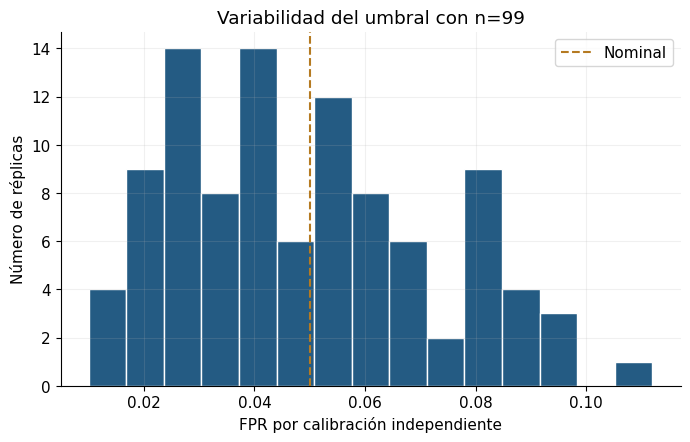

In [12]:
repeated=[]
for repeat in range(100):
    reference=rng_depth.normal(size=99)
    test=rng_depth.normal(size=500)
    cal=TailCalibrator(reference)
    repeated.append(np.mean([cal.alert(v,.05) for v in test]))
fig,ax=plt.subplots()
ax.hist(repeated,bins=15,color=BLUE,edgecolor='white')
ax.axvline(.05,color=GOLD,ls='--',label='Nominal')
ax.set(xlabel='FPR por calibración independiente',ylabel='Número de réplicas',title='Variabilidad del umbral con n=99')
ax.legend();plt.show()
print({'media_FPR':np.mean(repeated),'q10':np.quantile(repeated,.1),'q90':np.quantile(repeated,.9)})

### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### De falsas alertas individuales a FDR del lote

[Benjamini y Yekutieli, Annals of Statistics, 2001](https://doi.org/10.1214/aos/1013699998). Para p-valores marginalmente válidos, BY permite dependencia arbitraria:

$$k^*=\max\{k:p_{(k)}\le kq/(mH_m)\},\quad H_m=\sum_{j=1}^m1/j.$$

$$FDR=E[V/\max(R,1)].$$

BH omite $H_m$ y requiere supuestos adicionales de dependencia; Bonferroni controla otro objetivo, FWER. Ninguno transforma anomalías en fraude confirmado. Se trata de lotes fijos, no control online ilimitado.

### Comparadores y oráculo de frontera

Los empates se incluyen. La prueba mínima contrasta umbrales conocidos y preserva la correspondencia con cada caso.

In [13]:
def step_up(pvalues,q=.05,by=False):
    pvalues=np.asarray(pvalues,float)
    m=len(pvalues)
    order=np.argsort(pvalues)
    harmonic=np.sum(1/np.arange(1,m+1)) if by else 1.
    thresholds=q*np.arange(1,m+1)/(m*harmonic)
    eligible=np.flatnonzero(pvalues[order]<=thresholds)
    reject=np.zeros(m,dtype=bool)
    if len(eligible):reject=pvalues<=pvalues[order[eligible[-1]]]
    return reject

assert np.array_equal(step_up([.001,.02,.8]),[True,True,False])
assert not step_up([.1,.5,.9]).any()

### Calibración compartida y dependencia entre alertas

Se regeneran calibración y lote por réplica. Cada legítimo comparte su marginal normal con calibración, pero los casos de test tienen un factor común; no se supone PRDS para defender BH.

ACADEMIC_METRICS:{"batch_replicates": 400, "BY_FDR_by_rho": {"0.0": 0.005627525252525253, "0.7": 0.00045454545454545455}}


FDR    MCSE   power  alerts
rho policy                                    
0.0 BH          0.0547  0.0054  0.9255   9.870
    BY          0.0056  0.0018  0.6785   6.840
    Bonferroni  0.0039  0.0015  0.7335   7.370
    individual  0.3033  0.0078  0.9890  14.525
0.7 BH          0.0243  0.0084  0.8915   9.650
    BY          0.0005  0.0005  0.5895   5.900
    Bonferroni  0.0005  0.0005  0.6750   6.755
    individual  0.1197  0.0157  0.9910  13.530

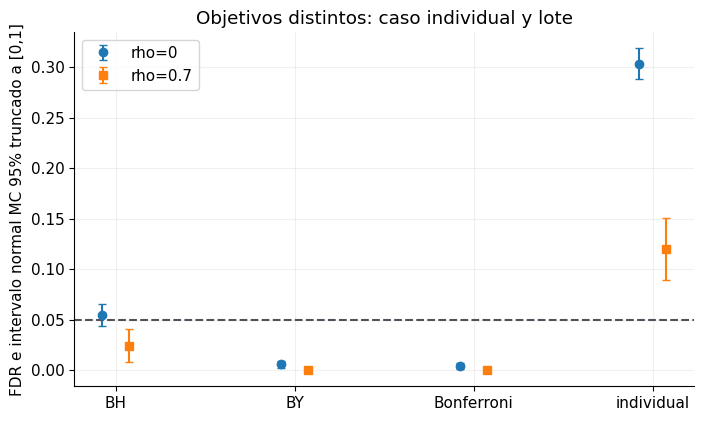

In [14]:
paper_rng=np.random.default_rng(2303)
batch_rows=[]
m=100;n_calibration=1999
for correlation in [0.,.7]:
    for repeat in range(200):
        reference=np.sort(paper_rng.normal(size=n_calibration))
        common=paper_rng.normal()
        scores=np.sqrt(correlation)*common+np.sqrt(1-correlation)*paper_rng.normal(size=m)
        truth=np.arange(m)>=90
        scores[truth]+=4.
        pvals=(1+n_calibration-np.searchsorted(reference,scores,side='left'))/(n_calibration+1)
        policies={'individual':pvals<=.05,'Bonferroni':pvals<=.05/m,
                  'BH':step_up(pvals),'BY':step_up(pvals,by=True)}
        for name,rejected in policies.items():
            discoveries=int(rejected.sum())
            false=int(np.sum(rejected & ~truth))
            batch_rows.append({'rho':correlation,'policy':name,'FDP':false/max(discoveries,1),
                               'power':float(np.sum(rejected & truth)/truth.sum()),'R':discoveries})
batch_table=pd.DataFrame(batch_rows)
batch_summary=batch_table.groupby(['rho','policy']).agg(FDR=('FDP','mean'),MCSE=('FDP',lambda x:x.std(ddof=1)/np.sqrt(len(x))),power=('power','mean'),alerts=('R','mean'))
display(batch_summary.round(4))
fig,ax=plt.subplots()
for j,(rho,g) in enumerate(batch_summary.groupby(level='rho')):
    labels=g.index.get_level_values('policy')
    ax.errorbar(np.arange(len(g))+(j-.5)*.15,g.FDR,yerr=[np.minimum(g.FDR,1.96*g.MCSE),np.minimum(1-g.FDR,1.96*g.MCSE)],fmt=['o','s'][j],capsize=3,label=f'rho={rho:g}')
ax.set_xticks(range(len(labels)),labels);ax.axhline(.05,color=GRAY,ls='--')
ax.set(ylabel='FDR e intervalo normal MC 95% truncado a [0,1]',title='Objetivos distintos: caso individual y lote')
ax.legend();plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'batch_replicates':400,'BY_FDR_by_rho':batch_summary.xs('BY',level='policy').FDR.to_dict()}))

### Ideas y cierre pendiente

Estudiar FDR online, etiquetas retrasadas y calibración contaminada. La simulación ilustra potencia/costo de BY; no prueba el teorema ni valida p-valores de una cartera real. La validez marginal debe verificarse antes de controlar multiplicidad.